# GHCF Ablation Sweep — Results Comparison

Compares all completed runs from the full factorial ablation sweep
(`checkpoints/sweep_full/manifest.jsonl`) across every swept axis:
`interaction_set`, `causal_mode` (incl. ACE fixed-blend splits), `bound_bfi`,
`freeze_sem`, `loss`, `adj_type`, `gnn_type`.

Re-run this notebook top to bottom any time the manifest gains more rows — it
only reads `manifest.jsonl` and works fine on a partial sweep.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

SWEEP_DIR = Path("../checkpoints/sweep_full")  # this notebook lives in Models/notebooks/
MANIFEST = SWEEP_DIR / "manifest.jsonl"
OUT_DIR = Path("sweep_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- palette (validated categorical order — see dataviz skill palette.md) ---
CATEGORICAL = ["#2a78d6", "#008300", "#e87ba4", "#eda100",
               "#1baf7a", "#eb6834", "#4a3aa7", "#e34948"]
INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID_COLOR = "#e1e0d9"
BASELINE = "#c3c2b7"
SURFACE = "#fcfcfb"

mpl.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_SECONDARY,
    "text.color": INK_PRIMARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "grid.color": GRID_COLOR,
    "grid.linewidth": 0.6,
    "axes.grid": True,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})


def color_for(i):
    return CATEGORICAL[i % len(CATEGORICAL)]


## Load & flatten the manifest

Only `status == "ok"` rows carry metrics. The manifest is append-only, so we keep the *last* record per tag (resume-safe) before filtering.

In [2]:
def load_manifest(path=MANIFEST):
    records = {}
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            r = json.loads(line)
            records[r["tag"]] = r  # last write per tag wins
    return records


records = load_manifest()

rows = []
for tag, r in records.items():
    if r["status"] != "ok":
        continue
    row = {
        "tag": tag,
        "interaction_set": r["interaction_set"],
        "causal_mode": r["causal_mode"],
        "bound_bfi": r["bound_bfi"],
        "freeze_sem": r["freeze_sem"],
        "loss": r["loss"],
        "adj_type": r["adj_type"],
        "gnn_type": r["gnn_type"],
        "wall_time_s": r["wall_time_s"],
    }
    for k, v in r["mean_metrics"].items():
        row[f"mean_{k}"] = v
    for k, v in r["std_metrics"].items():
        row[f"std_{k}"] = v
    rows.append(row)

df = pd.DataFrame(rows)

n_total = len(records)
n_ok = len(df)
n_other = n_total - n_ok
print(f"{n_ok} / {n_total} configs completed ok  ({n_other} failed or not yet run)")
df.head()


1080 / 1080 configs completed ok  (0 failed or not yet run)


,tag,interaction_set,causal_mode,bound_bfi,freeze_sem,loss,adj_type,gnn_type,wall_time_s,mean_precision@3,...,std_hit@3,std_precision@5,std_recall@5,std_ndcg@5,std_hit@5,std_precision@10,std_recall@10,std_ndcg@10,std_hit@10,std_auc
0,default_none_bb1_hybrid_norm_gcn,default,none,True,None,hybrid,norm,gcn,19685.146701,0.511111,...,0.133333,0.085375,0.009804,0.096982,0.066667,0.077889,0.020538,0.064443,0.000000,0.031000
1,default_none_bb1_mse_norm_gcn,default,none,True,None,mse,norm,gcn,29396.406493,0.522222,...,0.149071,0.061824,0.010573,0.100446,0.133333,0.026667,0.010476,0.066775,0.066667,0.008839
2,default_none_bb1_mse_norm_sage,default,none,True,None,mse,norm,sage,22608.631077,0.544444,...,0.124722,0.071802,0.009796,0.068340,0.066667,0.081377,0.016430,0.057380,0.000000,0.031872
3,default_none_bb1_mse_norm_gat,default,none,True,None,mse,norm,gat,23049.522937,0.522222,...,0.124722,0.084327,0.015085,0.097513,0.081650,0.062004,0.005756,0.060512,0.000000,0.027101
4,default_none_bb1_hybrid_norm_sage,default,none,True,None,hybrid,norm,sage,18165.368732,0.522222,...,0.105409,0.083267,0.014406,0.099862,0.081650,0.067987,0.021942,0.059081,0.000000,0.030912


In [3]:
METRIC_KEYS = [f"{m}@{k}" for m in ("precision", "recall", "ndcg", "hit") for k in (3, 5, 10)] + ["auc"]
MEAN_COLS = [f"mean_{m}" for m in METRIC_KEYS]
KEY_METRICS = ["mean_precision@10", "mean_recall@10", "mean_ndcg@10", "mean_hit@10", "mean_auc"]
KEY_METRICS_LABELS = ["precision@10", "recall@10", "ndcg@10", "hit@10", "auc"]
PRIMARY = "mean_recall@10"


## Leaderboard

Ranked by `recall@10` (the same primary metric `cross_validation.py` uses to pick the best/worst fold). Includes mean **and** std across the 5 CV folds for every metric.

In [4]:
MEAN_STD_COLS = []
for m in METRIC_KEYS:
    MEAN_STD_COLS.append(f"mean_{m}")
    MEAN_STD_COLS.append(f"std_{m}")

leaderboard_cols = ["tag", "interaction_set", "causal_mode", "bound_bfi", "freeze_sem",
                     "loss", "adj_type", "gnn_type", "wall_time_s"] + MEAN_STD_COLS
leaderboard = df.sort_values(PRIMARY, ascending=False)[leaderboard_cols].reset_index(drop=True)

display_cols = ["tag", "interaction_set", "causal_mode", "bound_bfi", "freeze_sem",
                 "gnn_type", "adj_type", "loss"]
top20 = leaderboard[display_cols].head(20).copy()
lb20 = leaderboard.head(20)
for label, key in zip(KEY_METRICS_LABELS, ["precision@10", "recall@10", "ndcg@10", "hit@10", "auc"]):
    top20[label] = (
        lb20[f"mean_{key}"].round(3).astype(str) + " ± " + lb20[f"std_{key}"].round(3).astype(str)
    )
top20


,tag,interaction_set,causal_mode,bound_bfi,freeze_sem,gnn_type,adj_type,loss,precision@10,recall@10,ndcg@10,hit@10,auc
0,default_ace_learnable_bb0_fs0_hybrid_mean_gcn,default,ace_learnable,False,False,gcn,mean,hybrid,0.46 ± 0.062,0.25 ± 0.05,0.734 ± 0.06,1.0 ± 0.0,0.519 ± 0.02
1,default_ace_fixed_5050_bb1_fs0_mse_mean_gcn,default,ace_fixed_5050,True,False,gcn,mean,mse,0.477 ± 0.068,0.248 ± 0.05,0.741 ± 0.043,1.0 ± 0.0,0.52 ± 0.027
2,default_ace_fixed_5050_bb1_fs0_mse_plain_gcn,default,ace_fixed_5050,True,False,gcn,plain,mse,0.48 ± 0.066,0.248 ± 0.043,0.728 ± 0.088,1.0 ± 0.0,0.528 ± 0.028
3,default_ace_fixed_7030_bb1_fs0_mse_mean_gcn,default,ace_fixed_7030,True,False,gcn,mean,mse,0.457 ± 0.045,0.248 ± 0.055,0.722 ± 0.06,1.0 ± 0.0,0.515 ± 0.041
4,default_ace_fixed_5050_bb0_fs0_mse_norm_gat,default,ace_fixed_5050,False,False,gat,norm,mse,0.473 ± 0.029,0.246 ± 0.04,0.747 ± 0.031,1.0 ± 0.0,0.497 ± 0.026
5,default_ace_learnable_bb1_fs0_mse_mean_gcn,default,ace_learnable,True,False,gcn,mean,mse,0.47 ± 0.076,0.245 ± 0.038,0.729 ± 0.039,1.0 ± 0.0,0.515 ± 0.025
6,default_ace_fixed_3070_bb0_fs0_mse_mean_gcn,default,ace_fixed_3070,False,False,gcn,mean,mse,0.473 ± 0.064,0.244 ± 0.024,0.721 ± 0.05,1.0 ± 0.0,0.504 ± 0.026
7,default_ace_learnable_bb1_fs0_mse_plain_gcn,default,ace_learnable,True,False,gcn,plain,mse,0.473 ± 0.058,0.243 ± 0.024,0.754 ± 0.076,1.0 ± 0.0,0.52 ± 0.02
8,default_ace_fixed_5050_bb1_fs0_mse_norm_gcn,default,ace_fixed_5050,True,False,gcn,norm,mse,0.47 ± 0.057,0.242 ± 0.028,0.736 ± 0.053,1.0 ± 0.0,0.518 ± 0.026
9,multiple_causal_bb1_fs0_mse_plain_gcn,multiple,causal,True,False,gcn,plain,mse,0.603 ± 0.057,0.241 ± 0.012,0.788 ± 0.042,1.0 ± 0.0,0.528 ± 0.027


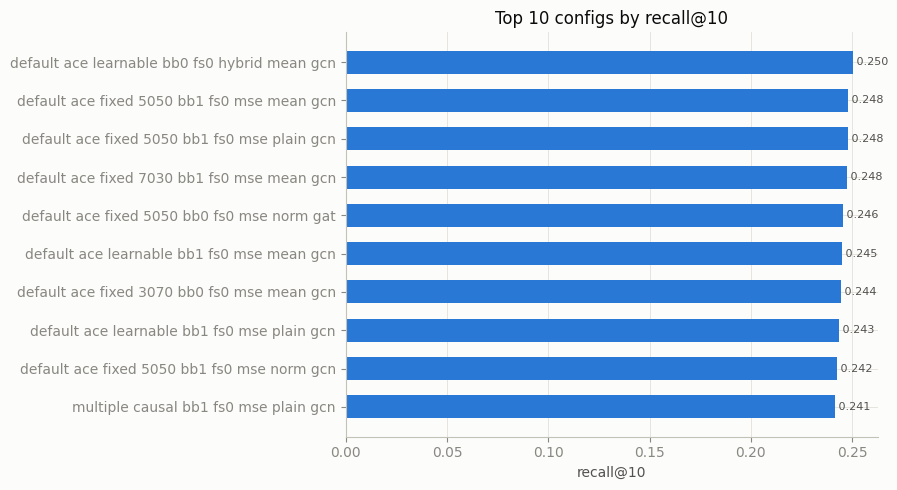

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
top10 = leaderboard.head(10).iloc[::-1]
labels = top10["tag"].str.replace("_", " ", regex=False)
ax.barh(labels, top10[PRIMARY], color=color_for(0), height=0.6)
ax.set_xlabel("recall@10")
ax.set_title("Top 10 configs by recall@10")
for y, v in enumerate(top10[PRIMARY]):
    ax.text(v, y, f" {v:.3f}", va="center", fontsize=8, color=INK_SECONDARY)
fig.tight_layout()
plt.show()


## Per-fold results

One row per (config, fold) — `fold` runs 1-5. Pulled from each run's
`cv_results.json` (`fold_results[i]["best_metrics"]`), not the manifest, since
the manifest only carries the already-aggregated mean/std.

In [6]:
def load_fold_results():
    fold_rows = []
    unreadable = 0
    for tag, r in records.items():
        if r["status"] != "ok" or not r.get("cv_dir"):
            continue
        try:
            with open(Path(r["cv_dir"]) / "cv_results.json") as f:
                cv_results = json.load(f)
        except Exception:
            unreadable += 1
            continue
        for fold in cv_results["fold_results"]:
            row = {
                "tag": tag,
                "interaction_set": r["interaction_set"],
                "causal_mode": r["causal_mode"],
                "bound_bfi": r["bound_bfi"],
                "freeze_sem": r["freeze_sem"],
                "loss": r["loss"],
                "adj_type": r["adj_type"],
                "gnn_type": r["gnn_type"],
                "fold": fold["fold_idx"] + 1,
                "training_time_s": fold.get("training_time"),
            }
            row.update(fold["best_metrics"])
            fold_rows.append(row)
    if unreadable:
        print(f"warning: {unreadable} 'ok' configs had an unreadable cv_results.json, skipped")
    return pd.DataFrame(fold_rows)


fold_df = load_fold_results()
print(f"{len(fold_df)} fold rows across {fold_df['tag'].nunique()} configs "
      f"({len(fold_df) / max(fold_df['tag'].nunique(), 1):.1f} folds/config)")
fold_df.head(10)


5400 fold rows across 1080 configs (5.0 folds/config)


,tag,interaction_set,causal_mode,bound_bfi,freeze_sem,loss,adj_type,gnn_type,fold,training_time_s,...,hit@3,precision@5,recall@5,ndcg@5,hit@5,precision@10,recall@10,ndcg@10,hit@10,auc
0,default_none_bb1_hybrid_norm_gcn,default,none,True,None,hybrid,norm,gcn,1,3344.524130,...,0.666667,0.466667,0.094686,0.670712,1.000000,0.500000,0.204962,0.713686,1.000000,0.477796
1,default_none_bb1_hybrid_norm_gcn,default,none,True,None,hybrid,norm,gcn,2,4245.464114,...,0.666667,0.400000,0.125163,0.559553,0.833333,0.466667,0.227652,0.647666,1.000000,0.443325
2,default_none_bb1_hybrid_norm_gcn,default,none,True,None,hybrid,norm,gcn,3,3341.393952,...,0.666667,0.533333,0.105439,0.789521,1.000000,0.466667,0.173296,0.780463,1.000000,0.447337
3,default_none_bb1_hybrid_norm_gcn,default,none,True,None,hybrid,norm,gcn,4,5719.011471,...,1.000000,0.633333,0.110278,0.817867,1.000000,0.650000,0.227222,0.812971,1.000000,0.500413
4,default_none_bb1_hybrid_norm_gcn,default,none,True,None,hybrid,norm,gcn,5,3006.453681,...,0.833333,0.600000,0.108408,0.787611,1.000000,0.616667,0.221517,0.814455,1.000000,0.524500
5,default_none_bb1_mse_norm_gcn,default,none,True,None,mse,norm,gcn,1,8301.601296,...,1.000000,0.500000,0.103290,0.765983,1.000000,0.550000,0.224462,0.764287,1.000000,0.480336
6,default_none_bb1_mse_norm_gcn,default,none,True,None,mse,norm,gcn,2,4036.103711,...,0.666667,0.466667,0.090523,0.544641,0.666667,0.550000,0.215636,0.639580,0.833333,0.463311
7,default_none_bb1_mse_norm_gcn,default,none,True,None,mse,norm,gcn,3,3178.586889,...,0.666667,0.533333,0.105439,0.783818,1.000000,0.516667,0.198459,0.809177,1.000000,0.469274
8,default_none_bb1_mse_norm_gcn,default,none,True,None,mse,norm,gcn,4,5402.471350,...,1.000000,0.633333,0.114444,0.831844,1.000000,0.600000,0.217500,0.827192,1.000000,0.467546
9,default_none_bb1_mse_norm_gcn,default,none,True,None,mse,norm,gcn,5,8450.835805,...,0.833333,0.466667,0.085155,0.687757,1.000000,0.550000,0.198898,0.727621,1.000000,0.453066


## Per-axis marginal comparison

For each swept axis, group all completed configs by that axis's value and
compare the mean metric across the group (marginalizing over every other
axis). Error bars are the standard deviation **across configs** in the group
(how much that axis's variants disagree), not the fold-level CV std.

In [7]:
def axis_compare_ax(ax, data, axis_col, metric_cols, metric_labels, title=None):
    sub = data.dropna(subset=[axis_col])
    if sub.empty:
        ax.axis("off")
        return None
    cats = sorted(sub[axis_col].unique(), key=str)
    stats = sub.groupby(axis_col)[metric_cols].agg(["mean", "std", "count"])
    n_cats = len(cats)
    width = 0.8 / max(n_cats, 1)
    x = np.arange(len(metric_cols))
    for i, cat in enumerate(cats):
        means = [stats.loc[cat, (m, "mean")] for m in metric_cols]
        stds = [stats.loc[cat, (m, "std")] or 0 for m in metric_cols]
        n = int(stats.loc[cat, (metric_cols[0], "count")])
        offset = (i - (n_cats - 1) / 2) * width
        ax.bar(x + offset, means, width * 0.9, yerr=stds, capsize=2,
               label=f"{cat} (n={n})", color=color_for(i), edgecolor="none")
    ax.set_xticks(x)
    ax.set_xticklabels(metric_labels, fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.02))
    return stats


def axis_compare(data, axis_col, metric_cols=KEY_METRICS, metric_labels=KEY_METRICS_LABELS,
                  title=None, figsize=None):
    fig, ax = plt.subplots(figsize=figsize or (1.7 * len(metric_cols) + 2.6, 4.2))
    stats = axis_compare_ax(ax, data, axis_col, metric_cols, metric_labels, title or axis_col)
    ax.set_ylabel("mean metric value")
    fig.tight_layout()
    return fig, stats


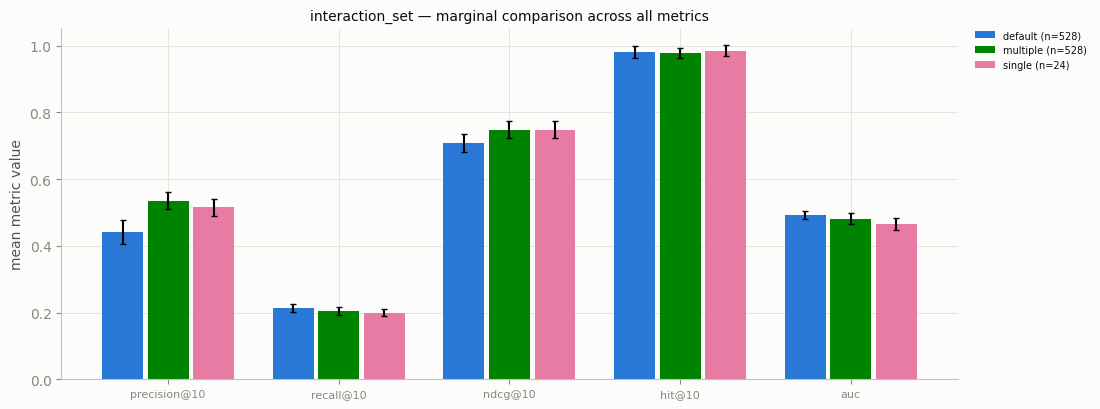

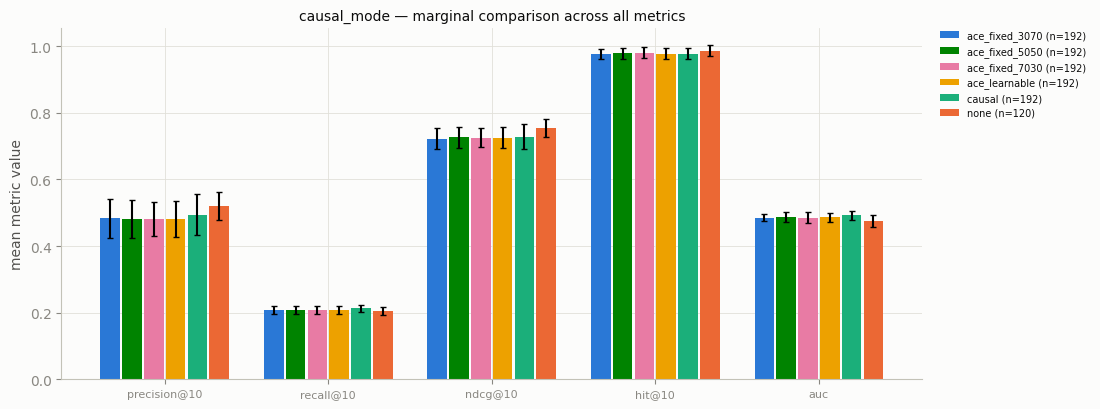

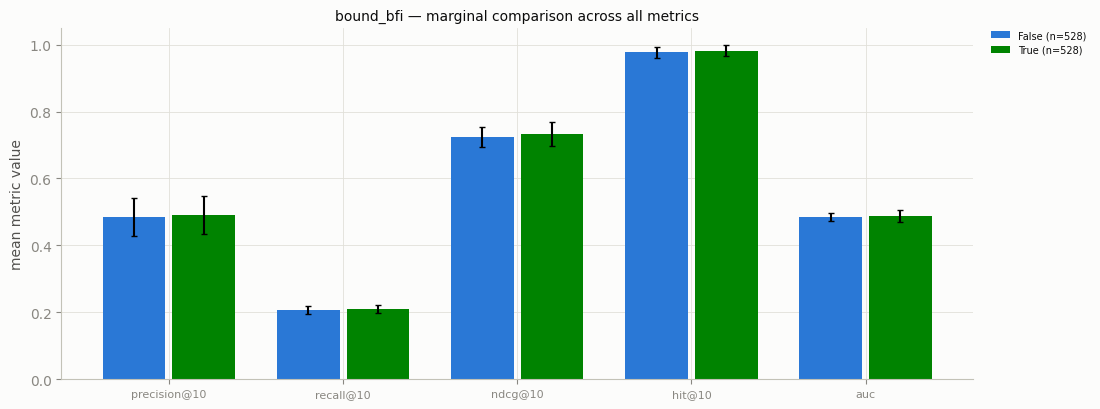

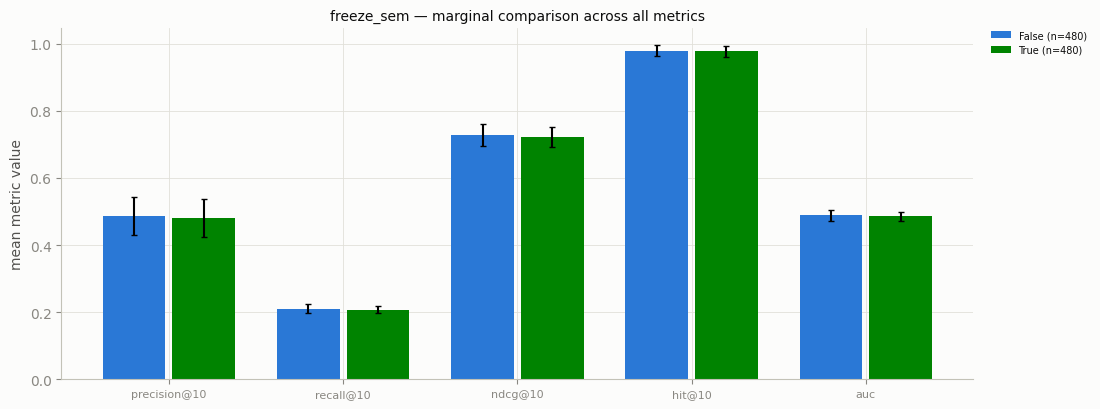

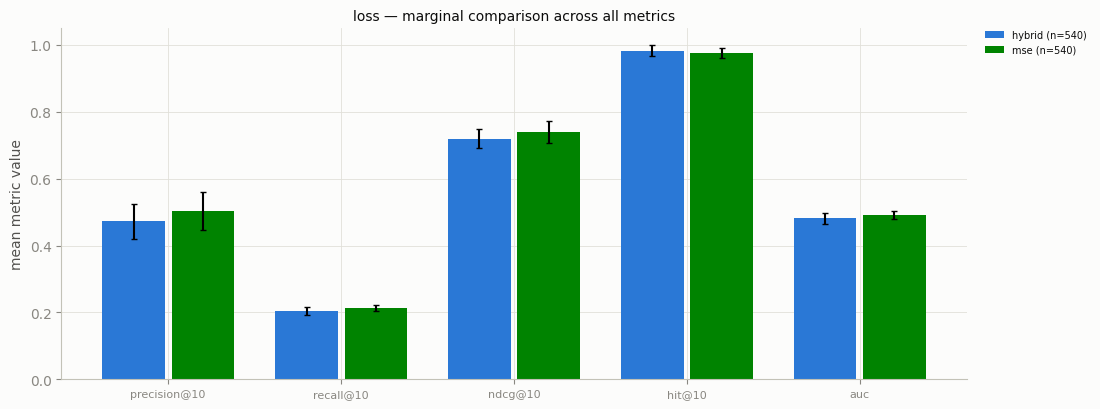

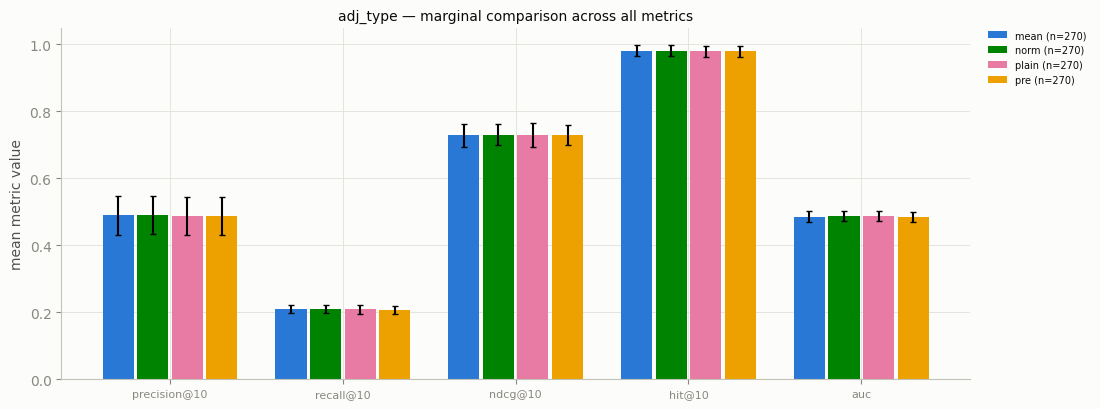

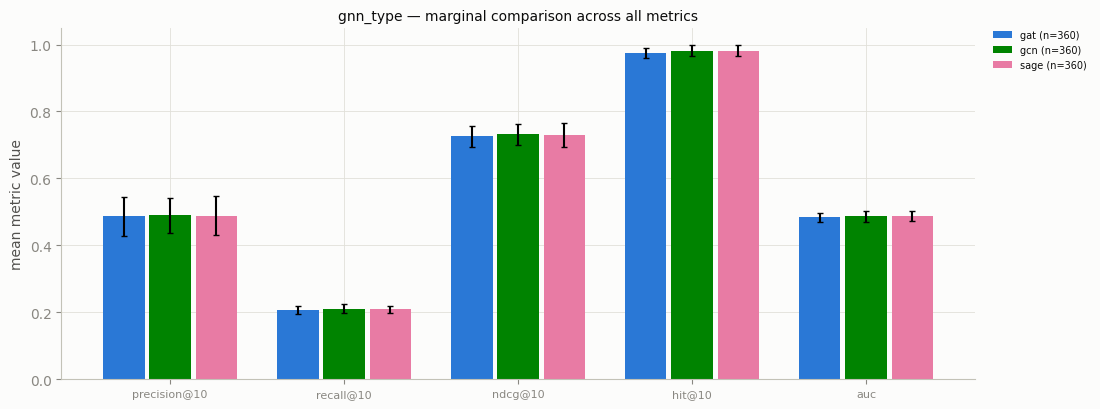

In [8]:
AXES = ["interaction_set", "causal_mode", "bound_bfi", "freeze_sem", "loss", "adj_type", "gnn_type"]
axis_stats = {}
for axis in AXES:
    fig, stats = axis_compare(df, axis, title=f"{axis} — marginal comparison across all metrics")
    axis_stats[axis] = stats
    plt.show()


## Causal-head deep dive: FREEZE_SEM x BOUND_BFI

Restricted to the causal-relevant modes (`causal`, `ace_learnable`, and the
three ACE fixed-blend splits) — `none` never uses `freeze_sem`/`bound_bfi`
meaningfully in the same way, so it's excluded here.

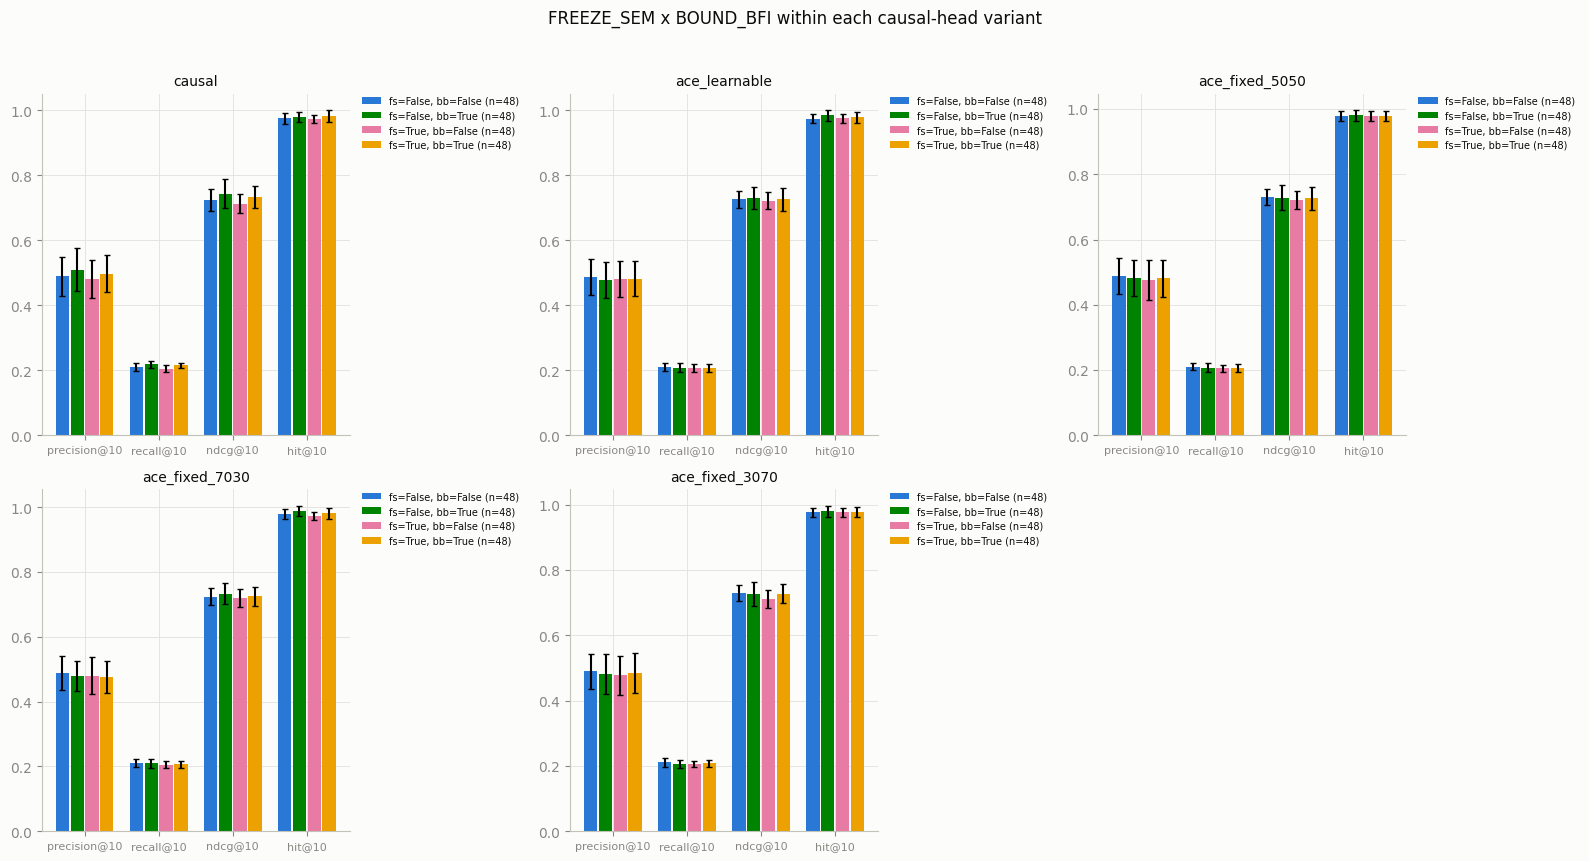

In [9]:
CAUSAL_RELEVANT = ["causal", "ace_learnable", "ace_fixed_5050", "ace_fixed_7030", "ace_fixed_3070"]
sub = df[df.causal_mode.isin(CAUSAL_RELEVANT)].copy()
sub["fs_bb"] = sub.apply(lambda r: f"fs={r.freeze_sem}, bb={r.bound_bfi}", axis=1)

present_modes = [m for m in CAUSAL_RELEVANT if m in sub.causal_mode.unique()]
n = len(present_modes)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.2 * nrows))
axes = np.atleast_1d(axes).flatten()
for ax, mode in zip(axes, present_modes):
    axis_compare_ax(ax, sub[sub.causal_mode == mode], "fs_bb",
                     KEY_METRICS[:4], KEY_METRICS_LABELS[:4], title=mode)
for ax in axes[len(present_modes):]:
    ax.axis("off")
fig.suptitle("FREEZE_SEM x BOUND_BFI within each causal-head variant", y=1.02)
fig.tight_layout()
plt.show()


## ACE fixed-blend weight comparison

`ace_learnable` (per-type learnable gate) vs. the three fixed `w_mlp`/`w_causal` splits swept for `ace_fixed_*`.

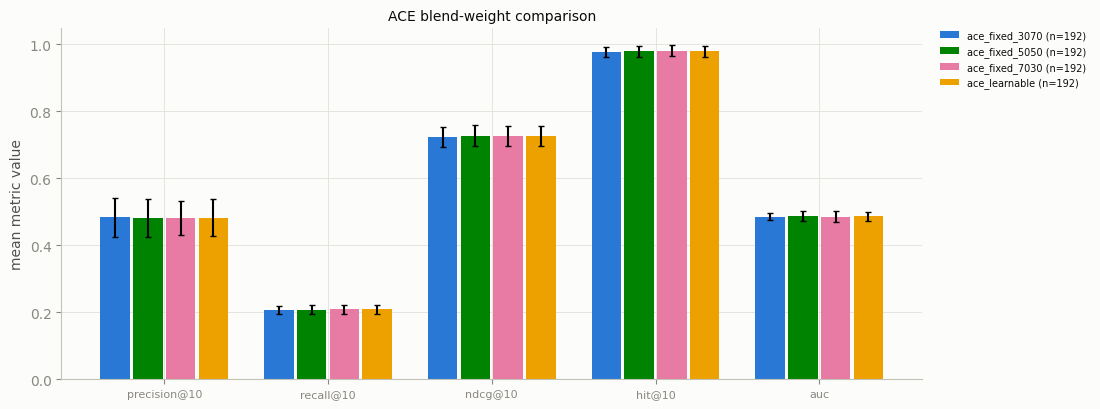

In [10]:
ACE_ONLY = ["ace_learnable", "ace_fixed_5050", "ace_fixed_7030", "ace_fixed_3070"]
fig, ace_stats = axis_compare(df[df.causal_mode.isin(ACE_ONLY)], "causal_mode",
                               title="ACE blend-weight comparison")
plt.show()


## GNN layer type x interaction set

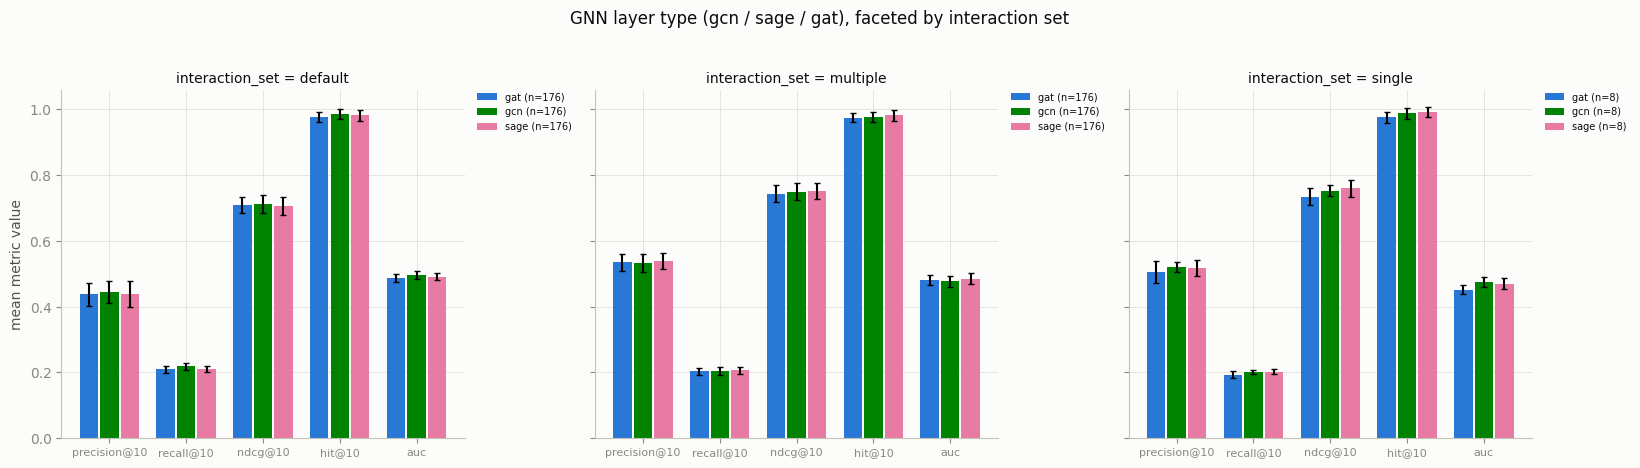

In [11]:
interaction_sets = sorted(df.interaction_set.dropna().unique())
fig, axes = plt.subplots(1, len(interaction_sets), figsize=(5.5 * len(interaction_sets), 4.5), sharey=True)
axes = np.atleast_1d(axes)
for ax, iset in zip(axes, interaction_sets):
    axis_compare_ax(ax, df[df.interaction_set == iset], "gnn_type",
                     KEY_METRICS, KEY_METRICS_LABELS, title=f"interaction_set = {iset}")
axes[0].set_ylabel("mean metric value")
fig.suptitle("GNN layer type (gcn / sage / gat), faceted by interaction set", y=1.03)
fig.tight_layout()
plt.show()


## Wall-time vs. quality (efficiency view)

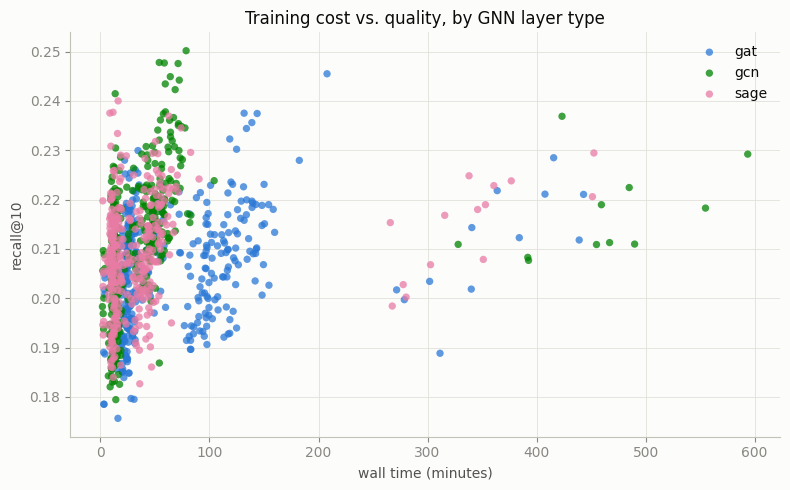

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
gnn_types = sorted(df.gnn_type.dropna().unique())
for i, g in enumerate(gnn_types):
    d = df[df.gnn_type == g]
    ax.scatter(d.wall_time_s / 60, d[PRIMARY], s=28, alpha=0.75,
               color=color_for(i), label=g, edgecolors="none")
ax.set_xlabel("wall time (minutes)")
ax.set_ylabel("recall@10")
ax.set_title("Training cost vs. quality, by GNN layer type")
ax.legend(frameon=False, title=None)
fig.tight_layout()
plt.show()


## Summary exports

All written to `notebooks/sweep_outputs/`:
- `sweep_results.xlsx` — two sheets: `leaderboard` (one row per config, mean **and**
  std of every metric) and `fold_results` (one row per config x fold, fold 1-5).
- `leaderboard_full.csv` / `fold_results.csv` — same two tables as plain CSV.
- `axis_summary_<axis>.csv` — mean/std/count per value of each swept axis, for every metric.

In [13]:
leaderboard.to_csv(OUT_DIR / "leaderboard_full.csv", index=False)
fold_df.to_csv(OUT_DIR / "fold_results.csv", index=False)

with pd.ExcelWriter(OUT_DIR / "sweep_results.xlsx", engine="openpyxl") as writer:
    leaderboard.to_excel(writer, sheet_name="leaderboard", index=False)
    fold_df.to_excel(writer, sheet_name="fold_results", index=False)

for axis, stats in axis_stats.items():
    flat = stats.copy()
    flat.columns = [f"{m}_{stat}" for m, stat in flat.columns]
    flat.to_csv(OUT_DIR / f"axis_summary_{axis}.csv")

print("Wrote:", sorted(p.name for p in OUT_DIR.glob("*")))


Wrote: ['axis_summary_adj_type.csv', 'axis_summary_bound_bfi.csv', 'axis_summary_causal_mode.csv', 'axis_summary_freeze_sem.csv', 'axis_summary_gnn_type.csv', 'axis_summary_interaction_set.csv', 'axis_summary_loss.csv', 'fold_results.csv', 'leaderboard_full.csv', 'sweep_results.xlsx']
